# Repaso de las partes C (desarrollo), la biblioteca de Lucía

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maximofernandezriera/toqui-devin-sync/blob/main/solucion-partes-c.ipynb)

Lucía es la bibliotecaria del barrio. Cada día presta y recoge libros, ordena signaturas en las estanterías, atiende la pequeña cafetería de la biblioteca y prepara la venta solidaria de ejemplares retirados. Para ahorrar tiempo se ha escrito pequeños programas en Python que le ayudan con estas tareas. En los strings de una estantería, `N` es una novela, `C` un cómic y `.` un hueco libre. Cada ejercicio es independiente: las variables empiezan de nuevo en cada uno y no hace falta haber resuelto los anteriores.

**Borrador.** *Material del docente. Contiene soluciones.*

## Cómo se ha corregido

### WHILE (18-11-2026)

- La parte C suma **12 puntos**: 4 puntos por cada función.
- Hay que escribir la función pedida en la hoja de respuestas y debe **devolver** el resultado, no imprimirlo.
- La rúbrica desglosada de cada ejercicio está transcrita en su sección, tal como aparece en el solucionario.
- Se aceptan algoritmos equivalentes que cumplan el contrato usando solo lo visto en clase (por ejemplo, `buscar_indice` con `while`, o `aplicar_descuento` resolviendo el tope en dos `if`).
- Nota de revisión del solucionario: en `contar_largas`, `split()` ya trata los espacios de los extremos; en `buscar_indice` se admite cualquier índice o recorrido equivalente; en `aplicar_descuento` no es obligatorio `append` si la lista nueva es correcta, conserva el orden y no cambia la original.

### C-V3

- El examen suma **30 puntos**: A, 8; B, 11; C, 11.
- Los errores de sintaxis no restan puntos.
- Se aceptan respuestas equivalentes con otro formato (por ejemplo, `NNCN` con comillas o «3 multados» en vez de «Multados: 3»).
- En C, la idea correcta puntúa aunque el código no funcione del todo.
- Si no hay código pero los resultados de los ejemplos son correctos, se concede 1 punto.

### D-V4

- El examen suma **30 puntos**: A, 8; B, 11; C, 11.
- Los errores de sintaxis no restan puntos.
- Se aceptan respuestas equivalentes con otro formato (por ejemplo, `NNCN` con comillas o «3 multados» en vez de «Multados: 3»).
- En C, la idea correcta puntúa aunque el código no funcione del todo.
- Si no hay código pero los resultados de los ejemplos son correctos, se concede 1 punto.

## Correspondencias cuaderno ↔ exámenes

| Cuaderno | En el examen | Puntos |
|---|---|---:|
| Ejercicio 1 | WHILE C1 | 4 |
| Ejercicio 2 | WHILE C2 | 4 |
| Ejercicio 3 | WHILE C3 | 4 |
| Ejercicio 4 | C-V3 C1 = D-V4 C2 | 3 |
| Ejercicio 5 | C-V3 C2 | 4 |
| Ejercicio 6 | C-V3 C3 = D-V4 C1 | 4 |
| Ejercicio 7 | D-V4 C3 | 4 |

## Caja de herramientas visual

Ejecutad esta celda una sola vez. Prepara la pizarra, las estanterías, el pasillo, el plano del carro y las tablas que usaremos durante el repaso.

In [1]:
#@title Caja de herramientas visual
import doctest
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

FONDO_PIZARRA = "#164638"
TIZA = "#f3f0df"
TIZA_AMARILLA = "#ffe36e"
TIZA_AZUL = "#a9d7ef"

def dibujar_pizarra(titulo, lineas, ancho=10, alto=3.3, guardar=None):
    """Dibuja una idea con texto y flechas sobre fondo de pizarra."""
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.045, 0.91, titulo, color=TIZA_AMARILLA, fontsize=17,
            fontweight="bold", family="DejaVu Sans Mono", va="top")
    cantidad = max(1, len(lineas))
    paso = 0.77 / cantidad
    tamano = 14 if cantidad <= 4 else 12
    for numero, linea in enumerate(lineas):
        if isinstance(linea, tuple):
            texto, color = linea
        else:
            texto, color = linea, TIZA
        ax.text(0.055, 0.78 - numero * paso, texto, color=color,
                fontsize=tamano, family="DejaVu Sans Mono", va="top",
                wrap=True)
    fig.tight_layout(pad=0.5)
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_estante(estante, marcar=(), titulo=""):
    """Dibuja las casillas de un estante con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(estante)), 2.2), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(0.05, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono", va="top")
    for i, letra in enumerate(estante):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, letra, ha="center", va="center",
                fontsize=20, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(estante)) + 0.15)
    ax.set_ylim(-0.55, 1.05)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_estantes_doble(antes, despues, titulo):
    """Compara dos estantes en la misma pizarra."""
    fig, ax = plt.subplots(figsize=(10, 3.1), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.03, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=16, fontweight="bold", family="DejaVu Sans Mono", va="top")
    ancho = max(len(antes), len(despues))
    for fila, (etiqueta, estante) in enumerate((("antes", antes), ("después", despues))):
        y = 0.60 - fila * 0.40
        ax.text(0.04, y + 0.10, etiqueta, transform=ax.transAxes,
                color=TIZA_AZUL, fontsize=13, family="DejaVu Sans Mono")
        for i, letra in enumerate(estante):
            x = 0.21 + 0.73 * i / max(1, ancho)
            w = 0.68 / max(1, ancho)
            ax.add_patch(Rectangle((x, y - 0.05), w, 0.23,
                                   transform=ax.transAxes,
                                   facecolor="#205b49",
                                   edgecolor=TIZA, linewidth=1.2))
            ax.text(x + w / 2, y + 0.065, letra, transform=ax.transAxes,
                    ha="center", va="center", fontsize=15, color=TIZA_AMARILLA,
                    family="DejaVu Sans Mono", fontweight="bold")
    display(fig)
    plt.close(fig)

def tabla_html(filas, columnas):
    """Construye una tabla estática para seguir una vuelta cada vez."""
    estilo = "border:1px solid #b8cbbf;padding:6px 14px;text-align:center;font-size:16px"
    cabecera = "".join(
        f'<th style="{estilo};background:#205b49;color:#fff">{c}</th>'
        for c in columnas
    )
    filas_html = "".join(
        "<tr>" + "".join(
            f'<td style="{estilo};color:#18382e">{fila[c]}</td>'
            for c in columnas
        ) + "</tr>"
        for fila in filas
    )
    return HTML(
        '<table style="border-collapse:collapse">'
        f"<tr>{cabecera}</tr>{filas_html}</table>"
    )

def traza_pasos(filas, columnas, pausa=0):
    """Presenta los datos de cada vuelta en orden."""
    display(tabla_html(filas, columnas))

def dibujar_tabla_pizarra(titulo, columnas, filas, guardar=None):
    """Dibuja una tabla de seguimiento legible en la pizarra."""
    fig, ax = plt.subplots(figsize=(10, max(2.8, 0.48 * (len(filas) + 2))), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.5, 0.96, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    izquierda, derecha = 0.05, 0.95
    arriba, abajo = 0.82, 0.08
    ancho = (derecha - izquierda) / len(columnas)
    alto = (arriba - abajo) / (len(filas) + 1)
    for r in range(len(filas) + 2):
        y = arriba - r * alto
        ax.plot([izquierda, derecha], [y, y], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    for c in range(len(columnas) + 1):
        x = izquierda + c * ancho
        ax.plot([x, x], [abajo, arriba], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    tabla = [columnas] + filas
    for r, fila in enumerate(tabla):
        for c, valor in enumerate(fila):
            x = izquierda + (c + 0.5) * ancho
            y = arriba - (r + 0.5) * alto
            ax.text(x, y, str(valor), transform=ax.transAxes, ha="center",
                    va="center", color=TIZA_AMARILLA if r == 0 else TIZA,
                    fontsize=12, family="DejaVu Sans Mono")
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_plano(ruta, titulo, guardar=None):
    """Plano en cuadrícula estilo pizarra con el recorrido del carro."""
    movimientos = {"N": (0, 1), "S": (0, -1), "E": (1, 0), "O": (-1, 0)}
    fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.set_xlim(-3.6, 3.6)
    ax.set_ylim(-2.9, 3.7)
    ax.set_aspect("equal")
    for gx in range(-3, 4):
        ax.axvline(gx, color="#3f6b5b", linewidth=0.7)
    for gy in range(-2, 4):
        ax.axhline(gy, color="#3f6b5b", linewidth=0.7)
    ax.axhline(0, color=TIZA, linewidth=1.2)
    ax.axvline(0, color=TIZA, linewidth=1.2)
    ax.set_xticks(range(-3, 4))
    ax.set_yticks(range(-2, 4))
    ax.tick_params(colors=TIZA, labelsize=9)
    for spine in ax.spines.values():
        spine.set_color(TIZA)
    ax.set_xlabel("x   (O  \u2190     \u2192  E)", color=TIZA, fontsize=10,
                  family="DejaVu Sans Mono")
    ax.set_ylabel("y   (S  \u2193     \u2191  N)", color=TIZA, fontsize=10,
                  family="DejaVu Sans Mono")
    ax.set_title(titulo, color=TIZA_AMARILLA, fontsize=13, fontweight="bold",
                 family="DejaVu Sans Mono")
    ax.plot(0, 0, marker="s", markersize=12, color=TIZA_AZUL)
    ax.annotate("mostrador\n(0, 0)", (0, 0), (0.3, -1.15), color=TIZA_AZUL,
                fontsize=9, family="DejaVu Sans Mono")
    x, y = 0, 0
    for paso, letra in enumerate(ruta, 1):
        dx, dy = movimientos[letra]
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x, y),
                    arrowprops={"arrowstyle": "-|>", "color": TIZA_AMARILLA,
                                "linewidth": 2})
        ax.text(x + dx / 2 + (0.16 if dx == 0 else 0),
                y + dy / 2 + (0.14 if dy == 0 else 0),
                f"{paso}:{letra}", color=TIZA, fontsize=9,
                family="DejaVu Sans Mono")
        x, y = x + dx, y + dy
    ax.plot(x, y, marker="o", markersize=9, color=TIZA_AMARILLA)
    desfase = 0.3 if movimientos[ruta[-1]][1] >= 0 else -0.9
    ax.annotate(f"acaba en [{x}, {y}]", (x, y), (x + 0.4, y + desfase),
                color=TIZA_AMARILLA, fontsize=10, family="DejaVu Sans Mono")
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_pasillo(ruta, titulo):
    """Dibuja el recorrido del carro desde el mostrador, posición cero."""
    fig, ax = plt.subplots(figsize=(9, 2.7), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-1.05, 1.7)
    ax.axis("off")
    ax.text(0.5, 0.98, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    ax.plot([-3, 3], [0, 0], color=TIZA, linewidth=2)
    for posicion in range(-3, 4):
        ax.add_patch(Rectangle((posicion - 0.34, -0.28), 0.68, 0.56,
                               facecolor="#205b49",
                               edgecolor=TIZA_AZUL if posicion == 0 else TIZA,
                               linewidth=2 if posicion == 0 else 1))
        ax.text(posicion, -0.58, str(posicion), ha="center", va="top",
                color=TIZA, fontsize=11, family="DejaVu Sans Mono")
    ax.text(0, 0.36, "mostrador", ha="center", color=TIZA_AZUL,
            fontsize=10, family="DejaVu Sans Mono")
    x = 0
    for paso, letra in enumerate(ruta, 1):
        nuevo_x = x + (1 if letra == "E" else -1)
        altura = 0.56 + 0.24 * (paso - 1)
        ax.annotate("", xy=(nuevo_x, altura), xytext=(x, altura),
                    arrowprops={"arrowstyle": "-|>", "color": TIZA_AMARILLA,
                                "linewidth": 2})
        ax.text((x + nuevo_x) / 2, altura + 0.10, f"{paso}:{letra}",
                ha="center", color=TIZA, fontsize=10,
                family="DejaVu Sans Mono")
        x = nuevo_x
    ax.plot(x, 0, marker="s", markersize=11, color=TIZA_AMARILLA,
            markeredgecolor=TIZA)
    ax.text(0.5, 0.02, f"fin: x = {x}", transform=ax.transAxes,
            ha="center", color=TIZA_AMARILLA, fontsize=12,
            family="DejaVu Sans Mono")
    display(fig)
    plt.close(fig)

print("Caja lista: pizarra, estantes, pasillo, plano y tablas.")


Caja lista: pizarra, estantes, pasillo, plano y tablas.


## Ejercicio 1 · Posición de un código reservado (WHILE C1 · 4 puntos)

### Enunciado exacto

Cabecera de la parte en el examen: «PARTE C - Desarrollo (12 puntos). Escribe la función pedida en la hoja de respuestas. Debe **devolver** el resultado (no imprimirlo). 4 puntos cada una.»

**C1 · Posición de un código reservado** (4 puntos)

Lucía tiene la lista de códigos de los libros reservados esta semana y quiere saber en qué posición está un código concreto (la primera posición es la 0).

Escribe la función `buscar_indice(valores, objetivo)` que reciba una lista y un valor, y devuelva la posición de la primera aparición de `objetivo` en `valores`, o `-1` si no está.

Ejemplos:

```text
buscar_indice([4, 7, 2, 7], 7)    ->  1
buscar_indice([4, 7, 2], 9)       ->  -1
```

### Pizarra

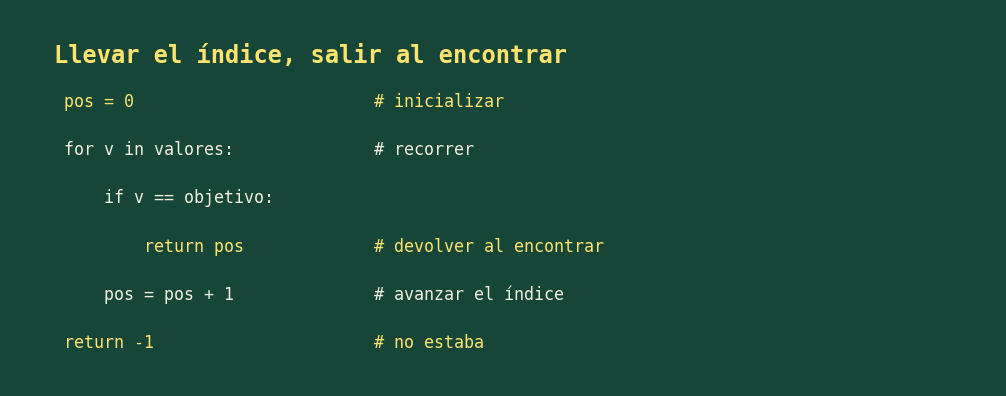

In [2]:
dibujar_pizarra(
    'Llevar el índice, salir al encontrar',
    [('pos = 0                        # inicializar', TIZA_AMARILLA),
    ('for v in valores:              # recorrer', TIZA),
    ('    if v == objetivo:', TIZA),
    ('        return pos             # devolver al encontrar', TIZA_AMARILLA),
    ('    pos = pos + 1              # avanzar el índice', TIZA),
    ('return -1                      # no estaba', TIZA_AMARILLA)],
    ancho=10, alto=3.9,
)

In [3]:
def buscar_indice(valores, objetivo):
    pos = 0                     # inicializar: posición actual
    for v in valores:           # recorrer
        if v == objetivo:
            return pos          # devolver al encontrar
        pos = pos + 1           # avanzar el índice
    return -1                   # no estaba

print(buscar_indice([4, 7, 2, 7], 7))
print(buscar_indice([4, 7, 2], 9))
print(buscar_indice([], 5))
print(buscar_indice([7], 7))

1
-1
-1
0


In [4]:
buscar_indice.__doc__ = """
>>> buscar_indice([4, 7, 2, 7], 7)
1
>>> buscar_indice([4, 7, 2], 9)
-1
>>> buscar_indice([], 5)
-1
>>> buscar_indice([7], 7)
0
"""
doctest.run_docstring_examples(buscar_indice, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(buscar_indice, "buscar_indice"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: buscar_indice")

Finding tests in NoName
Ejemplos verificados: buscar_indice


In [5]:
filas_e1 = [
    {"Vuelta": "1", "v": "4", "pos": "0", "¿v == objetivo?": "no, pos pasa a 1"},
    {"Vuelta": "2", "v": "7", "pos": "1", "¿v == objetivo?": "sí: return 1"},
]
traza_pasos(filas_e1, ["Vuelta", "v", "pos", "¿v == objetivo?"])

Vuelta,v,pos,¿v == objetivo?
1,4,0,"no, pos pasa a 1"
2,7,1,sí: return 1


**Paso a paso.** `pos` nace en 0 y acompaña al bucle como índice propio. En cada vuelta se compara el valor `v` con `objetivo`: si coincide, `return pos` entrega la posición en ese momento y la función termina; si no, `pos` avanza 1. Cuando el bucle termina sin encontrarlo, `return -1` señala que no estaba. La traza muestra `buscar_indice([4, 7, 2, 7], 7)`: sale en la segunda vuelta y devuelve la **primera** aparición.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20buscar_indice%28valores%2C%20objetivo%29%3A%0A%20%20%20%20pos%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%3A%20posici%C3%B3n%20actual%0A%20%20%20%20for%20v%20in%20valores%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20v%20%3D%3D%20objetivo%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20pos%20%20%20%20%20%20%20%20%20%20%23%20devolver%20al%20encontrar%0A%20%20%20%20%20%20%20%20pos%20%3D%20pos%20%2B%201%20%20%20%20%20%20%20%20%20%20%20%23%20avanzar%20el%20%C3%ADndice%0A%20%20%20%20return%20-1%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20no%20estaba%0Aprint%28buscar_indice%28%5B4%2C%207%2C%202%2C%207%5D%2C%207%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Firma según contrato. | 0,5 |
| Recorrido de la lista con índice propio. | 1 |
| Comparación y `return` de la posición en la primera aparición. | 1 |
| `return -1` tras el bucle. | 1 |
| Devuelve valor, no imprime. | 0,5 |

#### Errores frecuentes

- Devolver el valor `v` en lugar del índice `pos`.
- Olvidar `pos = pos + 1`: el índice no avanza y la función devuelve siempre 0.
- Poner `return -1` dentro del bucle: la función sale en la primera vuelta.
- Devolver `0` cuando no está: `0` es una posición válida; el contrato pide `-1`.
- Usar `print` en lugar de `return`.

## Ejercicio 2 · Palabras largas de una nota (WHILE C2 · 4 puntos)

### Enunciado exacto

**C2 · Palabras largas de una nota** (4 puntos)

Los socios del club de lectura dejan notas en papel con sus comentarios sobre los libros. Lucía quiere contar cuántas palabras largas tiene una nota, entendiendo por larga una palabra con una longitud estrictamente mayor que `minimo`.

Escribe la función `contar_largas(texto, minimo)` que reciba una cadena (puede tener espacios extra al principio y al final) y un entero `minimo`, y devuelva cuántas palabras tienen una longitud estrictamente mayor que `minimo`.

Ejemplos:

```text
contar_largas("hola mundo feliz", 4)    ->  2
contar_largas("", 5)                    ->  0
```

### Pizarra

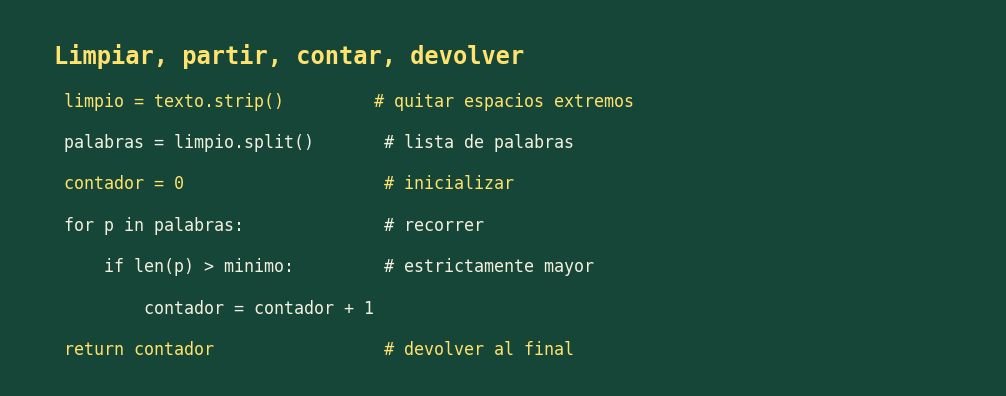

In [6]:
dibujar_pizarra(
    'Limpiar, partir, contar, devolver',
    [('limpio = texto.strip()         # quitar espacios extremos', TIZA_AMARILLA),
    ('palabras = limpio.split()       # lista de palabras', TIZA),
    ('contador = 0                    # inicializar', TIZA_AMARILLA),
    ('for p in palabras:              # recorrer', TIZA),
    ('    if len(p) > minimo:         # estrictamente mayor', TIZA),
    ('        contador = contador + 1', TIZA),
    ('return contador                 # devolver al final', TIZA_AMARILLA)],
    ancho=10, alto=3.9,
)

In [7]:
def contar_largas(texto, minimo):
    limpio = texto.strip()      # quitar espacios de los extremos
    palabras = limpio.split()   # lista de palabras; "" -> lista vacía
    contador = 0                # inicializar
    for p in palabras:          # recorrer
        if len(p) > minimo:     # estrictamente mayor
            contador = contador + 1
    return contador

print(contar_largas("hola mundo feliz", 4))
print(contar_largas("", 5))
print(contar_largas(" uno dos ", 2))
print(contar_largas("abc", 3))
print(contar_largas("palabra", 0))

2
0
2
0
1


In [8]:
contar_largas.__doc__ = """
>>> contar_largas("hola mundo feliz", 4)
2
>>> contar_largas("", 5)
0
>>> contar_largas(" uno dos ", 2)
2
>>> contar_largas("abc", 3)
0
>>> contar_largas("palabra", 0)
1
"""
doctest.run_docstring_examples(contar_largas, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(contar_largas, "contar_largas"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: contar_largas")

Finding tests in NoName
Ejemplos verificados: contar_largas


In [9]:
filas_e2 = [
    {"Vuelta": "1", "p": "hola", "len(p)": "4", "¿len(p) > 4?": "no", "contador": "0"},
    {"Vuelta": "2", "p": "mundo", "len(p)": "5", "¿len(p) > 4?": "sí", "contador": "1"},
    {"Vuelta": "3", "p": "feliz", "len(p)": "5", "¿len(p) > 4?": "sí", "contador": "2"},
]
traza_pasos(filas_e2, ["Vuelta", "p", "len(p)", "¿len(p) > 4?", "contador"])

Vuelta,p,len(p),¿len(p) > 4?,contador
1,hola,4,no,0
2,mundo,5,sí,1
3,feliz,5,sí,2


**Paso a paso.** `strip` quita los espacios de los extremos y `split` parte el texto en una lista de palabras; con una cadena vacía, `split` devuelve una lista vacía y el contador se queda en 0. Después el bucle suma 1 solo cuando `len(p)` es estrictamente mayor que `minimo`. La traza muestra `contar_largas("hola mundo feliz", 4)`: `hola` mide 4 y no cuenta porque 4 no es mayor que 4.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20contar_largas%28texto%2C%20minimo%29%3A%0A%20%20%20%20limpio%20%3D%20texto.strip%28%29%20%20%20%20%20%20%23%20quitar%20espacios%20de%20los%20extremos%0A%20%20%20%20palabras%20%3D%20limpio.split%28%29%20%20%20%23%20lista%20de%20palabras%3B%20%22%22%20-%3E%20lista%20vac%C3%ADa%0A%20%20%20%20contador%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20for%20p%20in%20palabras%3A%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20len%28p%29%20%3E%20minimo%3A%20%20%20%20%20%23%20estrictamente%20mayor%0A%20%20%20%20%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20return%20contador%0Aprint%28contar_largas%28%22hola%20mundo%20feliz%22%2C%204%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Firma según contrato. | 0,5 |
| `strip` + `split` correctos. | 1 |
| Condicional `len(p) > minimo` estricto. | 1 |
| Contador y `return` correctos. | 1 |
| Devuelve valor. | 0,5 |

#### Errores frecuentes

- Usar `>=` en lugar de `>`: `contar_largas("abc", 3)` debe dar 0.
- Contar los caracteres del texto entero en lugar de las palabras.
- Olvidar `strip`/`split`: los espacios se cuentan como si fueran caracteres de palabra.
- Poner `return` dentro del bucle: la función acaba en la primera palabra.
- Usar `print` en lugar de `return`.

## Ejercicio 3 · Rebajas de la venta solidaria (WHILE C3 · 4 puntos)

### Enunciado exacto

**C3 · Rebajas de la venta solidaria** (4 puntos)

La biblioteca organiza una venta solidaria con ejemplares retirados y algún producto de la cafetería. Lucía tiene los precios en una lista, en el orden en que están etiquetados, y quiere rebajarlos a todos por igual.

Escribe la función `aplicar_descuento(precios, rebaja)` que reciba una lista de precios y un número `rebaja`, y devuelva una **lista nueva** con cada precio reducido en `rebaja`. Ningún precio puede quedar por debajo de 0 y la lista original no debe cambiar.

Ejemplos:

```text
aplicar_descuento([2, 5], 1)    ->  [1, 4]
aplicar_descuento([1], 3)       ->  [0]
aplicar_descuento([], 2)        ->  []
```

### Pizarra

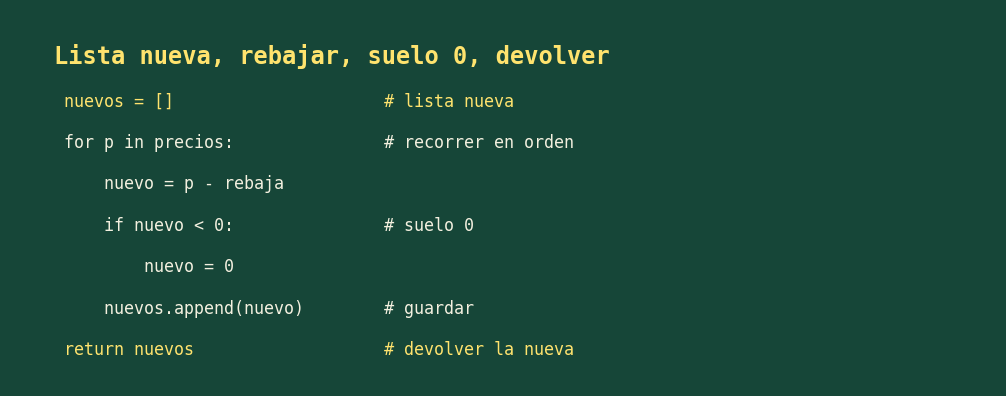

In [10]:
dibujar_pizarra(
    'Lista nueva, rebajar, suelo 0, devolver',
    [('nuevos = []                     # lista nueva', TIZA_AMARILLA),
    ('for p in precios:               # recorrer en orden', TIZA),
    ('    nuevo = p - rebaja', TIZA),
    ('    if nuevo < 0:               # suelo 0', TIZA),
    ('        nuevo = 0', TIZA),
    ('    nuevos.append(nuevo)        # guardar', TIZA),
    ('return nuevos                   # devolver la nueva', TIZA_AMARILLA)],
    ancho=10, alto=3.9,
)

In [11]:
def aplicar_descuento(precios, rebaja):
    nuevos = []                 # lista nueva, la original no se toca
    for p in precios:           # recorrer en orden
        nuevo = p - rebaja
        if nuevo < 0:           # suelo 0
            nuevo = 0
        nuevos.append(nuevo)    # guardar el precio rebajado
    return nuevos

print(aplicar_descuento([2, 5], 1))
print(aplicar_descuento([1], 3))
print(aplicar_descuento([], 2))
print(aplicar_descuento([3], 0))
print(aplicar_descuento([2, 10], 4))

[1, 4]
[0]
[]
[3]
[0, 6]


In [12]:
aplicar_descuento.__doc__ = """
>>> aplicar_descuento([2, 5], 1)
[1, 4]
>>> aplicar_descuento([1], 3)
[0]
>>> aplicar_descuento([], 2)
[]
>>> aplicar_descuento([3], 0)
[3]
>>> aplicar_descuento([2, 10], 4)
[0, 6]
>>> precios = [2, 5]
>>> aplicar_descuento(precios, 1)
[1, 4]
>>> precios
[2, 5]
"""
doctest.run_docstring_examples(aplicar_descuento, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(aplicar_descuento, "aplicar_descuento"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: aplicar_descuento")

Finding tests in NoName
Ejemplos verificados: aplicar_descuento


In [13]:
filas_e3 = [
    {"Vuelta": "1", "p": "2", "p - rebaja": "-2",
     "nuevo": "0", "nuevos": "[0]"},
    {"Vuelta": "2", "p": "10", "p - rebaja": "6",
     "nuevo": "6", "nuevos": "[0, 6]"},
]
traza_pasos(filas_e3, ["Vuelta", "p", "p - rebaja", "nuevo", "nuevos"])

Vuelta,p,p - rebaja,nuevo,nuevos
1,2,-2,0,[0]
2,10,6,6,"[0, 6]"


**Paso a paso.** La función crea una lista `nuevos` vacía y nunca escribe sobre `precios`, así la original queda intacta. En cada vuelta calcula `p - rebaja`; si el resultado baja de 0, el `if` lo deja en 0 (el suelo). `append` añade cada precio rebajado al final, con lo que `nuevos` conserva el orden de las etiquetas. La traza muestra `aplicar_descuento([2, 10], 4)`: `2 - 4` da `-2` y se corrige a `0`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20aplicar_descuento%28precios%2C%20rebaja%29%3A%0A%20%20%20%20nuevos%20%3D%20%5B%5D%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20lista%20nueva%2C%20la%20original%20no%20se%20toca%0A%20%20%20%20for%20p%20in%20precios%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%20en%20orden%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20p%20-%20rebaja%0A%20%20%20%20%20%20%20%20if%20nuevo%20%3C%200%3A%20%20%20%20%20%20%20%20%20%20%20%23%20suelo%200%0A%20%20%20%20%20%20%20%20%20%20%20%20nuevo%20%3D%200%0A%20%20%20%20%20%20%20%20nuevos.append%28nuevo%29%20%20%20%20%23%20guardar%20el%20precio%20rebajado%0A%20%20%20%20return%20nuevos%0Aprint%28aplicar_descuento%28%5B2%2C%205%5D%2C%201%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa una lista nueva vacía. | 1 |
| Recorre todos los precios en orden. | 1 |
| Calcula rebaja y aplica suelo 0. | 1 |
| Añade cada resultado y devuelve lista nueva sin cambiar original. | 1 |

Se aceptan algoritmos equivalentes.

#### Errores frecuentes

- Modificar `precios` en lugar de crear `nuevos`: el contrato exige una lista nueva y la original intacta.
- Olvidar el suelo 0: los precios no pueden quedar negativos.
- Poner `return` dentro del bucle: solo se rebaja el primer precio.
- Usar `print` en lugar de `return`.

## Ejercicio 4 · Contar novelas (C-V3 C1 = D-V4 C2 · 3 puntos)

### Enunciado exacto

C1. (3 pts) Inventario. Para el inventario, Lucía quiere saber cuántas novelas `N` hay en una estantería. Escribe `contar_novelas(estante)`, que devuelve cuántas novelas hay; los cómics y los huecos no cuentan.

```text
contar_novelas("NN.C")    ->  2
contar_novelas("CCN.N")   ->  2
contar_novelas("")        ->  0
```

> **Nota de equivalencia.** Este enunciado es el ejercicio C1 del modelo C-V3; en el modelo D-V4 aparece palabra por palabra como C2, con la misma puntuación (3 puntos). Solo cambia el número de ejercicio.

### Pizarra

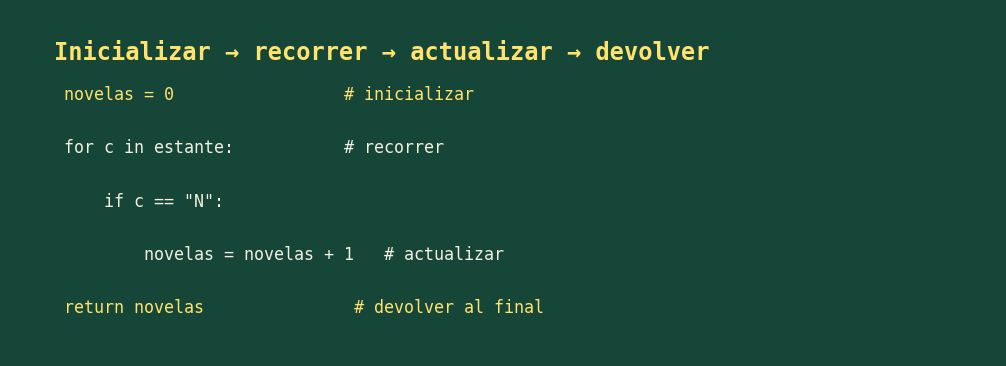

In [14]:
dibujar_pizarra(
    'Inicializar → recorrer → actualizar → devolver',
    [('novelas = 0                 # inicializar', TIZA_AMARILLA),
    ('for c in estante:           # recorrer', TIZA),
    ('    if c == "N":', TIZA),
    ('        novelas = novelas + 1   # actualizar', TIZA),
    ('return novelas               # devolver al final', TIZA_AMARILLA)],
    ancho=10, alto=3.6,
)

In [15]:
def contar_novelas(estante):
    novelas = 0                 # inicializar
    for c in estante:           # recorrer
        if c == "N":
            novelas = novelas + 1   # actualizar
    return novelas

print(contar_novelas("NN.C"))
print(contar_novelas("CCN.N"))
print(contar_novelas(""))

2
2
0


In [16]:
contar_novelas.__doc__ = """
>>> contar_novelas("NN.C")
2
>>> contar_novelas("CCN.N")
2
>>> contar_novelas("")
0
"""
doctest.run_docstring_examples(contar_novelas, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(contar_novelas, "contar_novelas"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: contar_novelas")

Finding tests in NoName
Ejemplos verificados: contar_novelas


In [17]:
filas_e4 = [
    {"Vuelta": "1", "c": "N", '¿c == "N"?': "sí", "novelas": "1"},
    {"Vuelta": "2", "c": "N", '¿c == "N"?': "sí", "novelas": "2"},
    {"Vuelta": "3", "c": ".", '¿c == "N"?': "no", "novelas": "2"},
    {"Vuelta": "4", "c": "C", '¿c == "N"?': "no", "novelas": "2"},
]
traza_pasos(filas_e4, ["Vuelta", "c", '¿c == "N"?', "novelas"])

Vuelta,c,"¿c == ""N""?",novelas
1,N,sí,1
2,N,sí,2
3,.,no,2
4,C,no,2


**Paso a paso.** El contador nace en 0 antes del bucle. El `for` recorre cada carácter; solo cuando `c` es `N` se suma 1. El `return` está al final, fuera del bucle, para devolver el total después de revisar toda la estantería.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20contar_novelas%28estante%29%3A%0A%20%20%20%20novelas%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20for%20c%20in%20estante%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20c%20%3D%3D%20%22N%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20novelas%20%3D%20novelas%20%2B%201%20%20%20%23%20actualizar%0A%20%20%20%20return%20novelas%0Aprint%28contar_novelas%28%22NN.C%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa el contador a 0 fuera del bucle. | 1 |
| Recorre la estantería con una condición dentro del bucle. | 1 |
| Suma dentro del bucle y devuelve el total al final. | 1 |
| Si usa `print` en lugar de `return`. | -1 |

#### Errores frecuentes

- Poner `return` dentro del bucle: la función acaba en la primera letra.
- Usar `print` en lugar de `return` cuando el enunciado pide devolver.

## Ejercicio 5 · Recorrer el pasillo (C-V3 C2 · 4 puntos)

### Enunciado exacto

C2. (4 pts) El carro de devoluciones. Lucía empuja el carro con los libros devueltos por el pasillo principal de la biblioteca para dejarlos en su sitio. Las estanterías del pasillo están numeradas en fila: el mostrador es la posición `0`, las de la derecha son `1`, `2`, `3`... y las de la izquierda `-1`, `-2`, `-3`... Lucía siempre sale del mostrador.

La ruta es un string en el que cada letra mueve el carro una posición:

| Letra | Dirección | Qué cambia |
|---|---|---|
| E | este (derecha) | x aumenta 1 |
| O | oeste (izquierda) | x disminuye 1 |

Por ejemplo, con la ruta `EEO` el carro hace tres movimientos:

| Paso | Letra | x |
|---|---|---:|
| inicio |  | 0 |
| 1 | E | 1 |
| 2 | E | 2 |
| 3 | O | 1 |

Escribe `posicion_final(ruta)`, que devuelve la posición `x` donde acaba el carro. Si la ruta está vacía, el carro no se mueve.

```text
posicion_final("EEO")     ->  1
posicion_final("OO")      ->  -2
posicion_final("EOEO")    ->  0
```

> **Nota.** En el Ejercicio 7 aparece otra función llamada `posicion_final`, la del plano del modelo D-V4. Son funciones distintas con el mismo nombre; ahí se explica con detalle.

### Pizarra

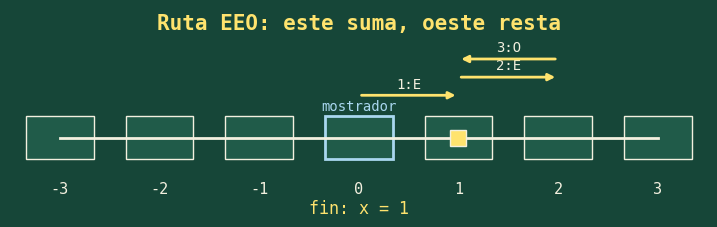

In [18]:
dibujar_pasillo("EEO", "Ruta EEO: este suma, oeste resta")

In [19]:
def posicion_final(ruta):
    x = 0                       # inicializar
    for paso in ruta:           # recorrer
        if paso == "E":
            x = x + 1           # actualizar
        elif paso == "O":
            x = x - 1
    return x

print(posicion_final("EEO"))
print(posicion_final("OO"))
print(posicion_final("EOEO"))

1
-2
0


In [20]:
posicion_final.__doc__ = """
>>> posicion_final("EEO")
1
>>> posicion_final("OO")
-2
>>> posicion_final("EOEO")
0
"""
doctest.run_docstring_examples(posicion_final, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(posicion_final, "posicion_final"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: posicion_final")

Finding tests in NoName
Ejemplos verificados: posicion_final


In [21]:
filas_e5 = [
    {"Paso": "inicio", "Letra": "", "x": "0"},
    {"Paso": "1", "Letra": "E", "x": "1"},
    {"Paso": "2", "Letra": "E", "x": "2"},
    {"Paso": "3", "Letra": "O", "x": "1"},
]
traza_pasos(filas_e5, ["Paso", "Letra", "x"])

Paso,Letra,x
inicio,,0
1,E,1
2,E,2
3,O,1


**Paso a paso.** La posición `x` empieza en 0. Cada `E` suma 1 y cada `O` resta 1. El bucle procesa la ruta letra a letra y `return x` devuelve la posición final. Si la ruta está vacía, no hay vueltas y se devuelve 0.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20posicion_final%28ruta%29%3A%0A%20%20%20%20x%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20for%20paso%20in%20ruta%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20paso%20%3D%3D%20%22E%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20x%20%3D%20x%20%2B%201%20%20%20%20%20%20%20%20%20%20%20%23%20actualizar%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22O%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20x%20%3D%20x%20-%201%0A%20%20%20%20return%20x%0Aprint%28posicion_final%28%22EEO%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa `x` a 0 fuera del bucle. | 1 |
| Recorre la ruta con una condición sobre la letra. | 1 |
| Actualiza `x` dentro del bucle. | 1 |
| Devuelve `x` al final. | 1 |

#### Errores frecuentes

- Poner `return` dentro del bucle: la ruta se detendría tras la primera letra.
- Escribir la función sin un bucle `for`.
- Usar la misma variable para la letra de la ruta y para la posición.
- Confundirla con la `posicion_final` del Ejercicio 7, que devuelve la lista `[x, y]`.
- Usar `print` en lugar de `return`.

## Ejercicio 6 · Devolver posiciones de huecos (C-V3 C3 = D-V4 C1 · 4 puntos)

### Enunciado exacto

C3. (4 pts) Huecos libres. Escribe `huecos(estante)`, que devuelve una lista con las posiciones de los huecos libres `.` de la estantería, de izquierda a derecha. La primera posición es la 0.

Pista: recorre las posiciones con `for i in range(len(estante)):` y mira la letra `estante[i]`.

```text
huecos("N..C.")   ->  [1, 2, 4]
huecos("NNC")     ->  []
```

> **Nota de equivalencia.** Este enunciado es el ejercicio C3 del modelo C-V3; en el modelo D-V4 aparece palabra por palabra como C1, con la misma puntuación (4 puntos). Solo cambia el número de ejercicio.

### Pizarra

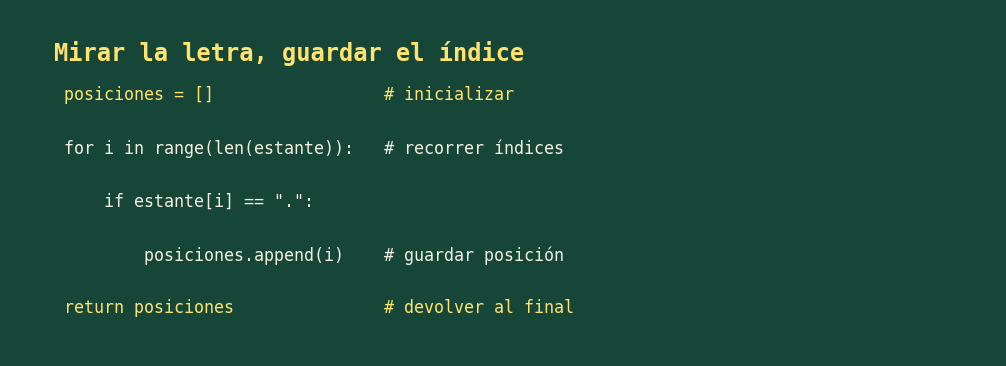

In [22]:
dibujar_pizarra(
    'Mirar la letra, guardar el índice',
    [('posiciones = []                 # inicializar', TIZA_AMARILLA),
    ('for i in range(len(estante)):   # recorrer índices', TIZA),
    ('    if estante[i] == ".":', TIZA),
    ('        posiciones.append(i)    # guardar posición', TIZA),
    ('return posiciones               # devolver al final', TIZA_AMARILLA)],
    ancho=10, alto=3.6,
)

In [23]:
def huecos(estante):
    posiciones = []             # inicializar
    for i in range(len(estante)):   # recorrer
        if estante[i] == ".":
            posiciones.append(i)    # actualizar
    return posiciones

print(huecos("N..C."))
print(huecos("NNC"))

[1, 2, 4]
[]


In [24]:
huecos.__doc__ = """
>>> huecos("N..C.")
[1, 2, 4]
>>> huecos("NNC")
[]
"""
doctest.run_docstring_examples(huecos, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(huecos, "huecos"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: huecos")

Finding tests in NoName
Ejemplos verificados: huecos


In [25]:
filas_e6 = [
    {"Vuelta": "1", "i": "0", "estante[i]": "N", "posiciones": "[]"},
    {"Vuelta": "2", "i": "1", "estante[i]": ".", "posiciones": "[1]"},
    {"Vuelta": "3", "i": "2", "estante[i]": ".", "posiciones": "[1, 2]"},
    {"Vuelta": "4", "i": "3", "estante[i]": "C", "posiciones": "[1, 2]"},
    {"Vuelta": "5", "i": "4", "estante[i]": ".", "posiciones": "[1, 2, 4]"},
]
traza_pasos(filas_e6, ["Vuelta", "i", "estante[i]", "posiciones"])

Vuelta,i,estante[i],posiciones
1,0,N,[]
2,1,.,[1]
3,2,.,"[1, 2]"
4,3,C,"[1, 2]"
5,4,.,"[1, 2, 4]"


**Paso a paso.** `range(len(estante))` produce las posiciones 0, 1, 2... En cada posición comprobamos el carácter con `estante[i]`. Si es `.`, añadimos `i` a la lista. Al terminar el recorrido devolvemos la lista de posiciones, no una lista de letras.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20huecos%28estante%29%3A%0A%20%20%20%20posiciones%20%3D%20%5B%5D%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20for%20i%20in%20range%28len%28estante%29%29%3A%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20estante%5Bi%5D%20%3D%3D%20%22.%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20posiciones.append%28i%29%20%20%20%20%23%20actualizar%0A%20%20%20%20return%20posiciones%0Aprint%28huecos%28%22N..C.%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa la lista vacía fuera del bucle. | 1 |
| Recorre por posiciones (`range`/`len` o `enumerate`). | 1 |
| La condición compara `estante[i]` con `"."`. | 1 |
| Añade la posición y devuelve la lista. | 1 |

#### Errores frecuentes

- Comparar el índice `i` con la letra en lugar de mirar `estante[i]`.
- Añadir `estante[i]` o el estante entero en vez de añadir `i`.
- Usar `print` en lugar de `return`.

## Ejercicio 7 · El carro en cuatro direcciones (D-V4 C3 · 4 puntos)

### Enunciado exacto

C3. (4 pts) El carro de devoluciones. Lucía recorre la biblioteca empujando el carro con los libros devueltos para dejarlos en su sitio. El plano de la biblioteca es una cuadrícula: cada casilla tiene dos coordenadas, `x` (izquierda-derecha) e `y` (abajo-arriba). Lucía siempre sale del mostrador, la casilla `(0, 0)`.

La ruta es un string en el que cada letra mueve el carro una casilla:

| Letra | Dirección | Qué cambia |
|---|---|---|
| N | norte (arriba) | y aumenta 1 |
| S | sur (abajo) | y disminuye 1 |
| E | este (derecha) | x aumenta 1 |
| O | oeste (izquierda) | x disminuye 1 |

Por ejemplo, con la ruta `NNE` el carro hace tres movimientos:

| Paso | Letra | x | y |
|---|---|---:|---:|
| inicio |  | 0 | 0 |
| 1 | N | 0 | 1 |
| 2 | N | 0 | 2 |
| 3 | E | 1 | 2 |

Escribe `posicion_final(ruta)`, que devuelve la lista `[x, y]` donde acaba el carro. Si la ruta está vacía, el carro no se mueve.

```text
posicion_final("NNE")    ->  [1, 2]
posicion_final("OOS")    ->  [-2, -1]
posicion_final("NSEO")   ->  [0, 0]
```

> **Nota.** En este cuaderno hay dos funciones llamadas `posicion_final` porque los dos exámenes eligieron el mismo nombre para ejercicios distintos: la del Ejercicio 5 (pasillo, C-V3) devuelve la posición `x`, un entero, y esta (plano, D-V4) devuelve la lista `[x, y]`. Python se queda con la última definición ejecutada; por eso el doctest del Ejercicio 5 se verificó allí mismo, justo después de su definición, antes de llegar a esta.

### Pizarra

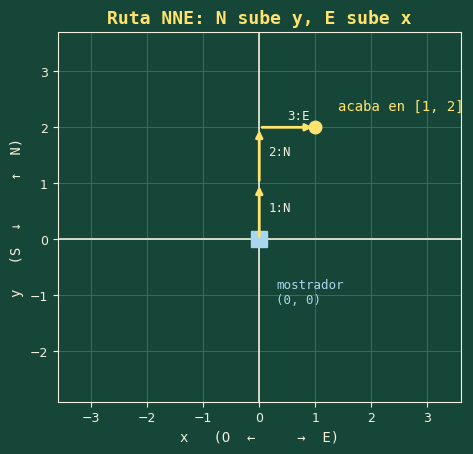

In [26]:
dibujar_plano("NNE", "Ruta NNE: N sube y, E sube x")

In [27]:
def posicion_final(ruta):
    x = 0                       # inicializar
    y = 0
    for paso in ruta:           # recorrer
        if paso == "N":
            y = y + 1           # actualizar
        elif paso == "S":
            y = y - 1
        elif paso == "E":
            x = x + 1
        elif paso == "O":
            x = x - 1
    return [x, y]

print(posicion_final("NNE"))
print(posicion_final("OOS"))
print(posicion_final("NSEO"))

[1, 2]
[-2, -1]
[0, 0]


In [28]:
posicion_final.__doc__ = """
>>> posicion_final("NNE")
[1, 2]
>>> posicion_final("OOS")
[-2, -1]
>>> posicion_final("NSEO")
[0, 0]
"""
doctest.run_docstring_examples(posicion_final, globals(), verbose=True)
runner = doctest.DocTestRunner()
for ejemplo in doctest.DocTestFinder().find(posicion_final, "posicion_final"):
    runner.run(ejemplo)
resultado = runner.summarize()
assert resultado.failed == 0
print("Ejemplos verificados: posicion_final")

Finding tests in NoName
Ejemplos verificados: posicion_final


In [29]:
filas_e7 = [
    {"Paso": "inicio", "Letra": "", "x": "0", "y": "0"},
    {"Paso": "1", "Letra": "N", "x": "0", "y": "1"},
    {"Paso": "2", "Letra": "N", "x": "0", "y": "2"},
    {"Paso": "3", "Letra": "E", "x": "1", "y": "2"},
]
traza_pasos(filas_e7, ["Paso", "Letra", "x", "y"])

Paso,Letra,x,y
inicio,,0,0
1,N,0,1
2,N,0,2
3,E,1,2


**Paso a paso.** Ahora hay **dos contadores**: `x` se mueve con E (suma) y O (resta); `y` se mueve con N (suma) y S (resta). El bucle procesa la ruta letra a letra y `return [x, y]` devuelve la lista de las dos coordenadas. Si la ruta está vacía, no hay vueltas y se devuelve `[0, 0]`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20posicion_final%28ruta%29%3A%0A%20%20%20%20x%20%3D%200%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%23%20inicializar%0A%20%20%20%20y%20%3D%200%0A%20%20%20%20for%20paso%20in%20ruta%3A%20%20%20%20%20%20%20%20%20%20%20%23%20recorrer%0A%20%20%20%20%20%20%20%20if%20paso%20%3D%3D%20%22N%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20y%20%3D%20y%20%2B%201%20%20%20%20%20%20%20%20%20%20%20%23%20actualizar%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22S%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20y%20%3D%20y%20-%201%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22E%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20x%20%3D%20x%20%2B%201%0A%20%20%20%20%20%20%20%20elif%20paso%20%3D%3D%20%22O%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20x%20%3D%20x%20-%201%0A%20%20%20%20return%20%5Bx%2C%20y%5D%0Aprint%28posicion_final%28%22NNE%22%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Inicializa `x` e `y` a 0 fuera del bucle. | 1 |
| Recorre la ruta con una condición por letra. | 1 |
| Actualiza `x` e `y` dentro del bucle. | 1 |
| Devuelve la lista `[x, y]` al final. | 1 |

#### Errores frecuentes

- Devolver un solo número en lugar de la lista `[x, y]`.
- Sumar la `N` o la `S` a `x`, o la `E`/`O` a `y`.
- Poner `return` dentro del bucle: la ruta se detendría tras la primera letra.
- Confundirla con la `posicion_final` del Ejercicio 5, que devuelve solo `x`.
- Usar `print` en lugar de `return`.

# Resumen final

| Cuaderno | En el examen | Respuesta oficial | Puntos |
|---|---|---|---:|
| Ejercicio 1 | WHILE C1 | `buscar_indice`: 1, -1, -1, 0 | 4 |
| Ejercicio 2 | WHILE C2 | `contar_largas`: 2, 0, 2, 0, 1 | 4 |
| Ejercicio 3 | WHILE C3 | `aplicar_descuento`: [1, 4], [0], [], [3], [0, 6] | 4 |
| Ejercicio 4 | C-V3 C1 = D-V4 C2 | `contar_novelas`: 2, 2, 0 | 3 |
| Ejercicio 5 | C-V3 C2 | `posicion_final` del pasillo: 1, -2, 0 | 4 |
| Ejercicio 6 | C-V3 C3 = D-V4 C1 | `huecos`: [1, 2, 4], [] | 4 |
| Ejercicio 7 | D-V4 C3 | `posicion_final` del plano: [1, 2], [-2, -1], [0, 0] | 4 |
| **Total WHILE** | C1, C2, C3 | | **12** |
| **Total C-V3** | C1, C2, C3 | | **11** |
| **Total D-V4** | C1, C2, C3 | | **11** |

## Dudas frecuentes

**¿Por qué `buscar_indice` devuelve `-1` y no `0`?**  
`0` ya es una posición válida (la primera de la lista). El `-1` es la señal de «no estaba», para que no se confunda con un índice real.

**¿`return` dentro o fuera del bucle?**  
Depende del contrato. En `buscar_indice` hay un `return` dentro del bucle (salir al encontrar) y otro fuera (el `-1` final). En `contar_novelas`, `huecos` o `aplicar_descuento` el `return` va siempre fuera: dentro del bucle acabaría la función en la primera vuelta.

**¿Por qué `contar_largas("abc", 3)` da 0?**  
El enunciado pide longitud «estrictamente mayor» que `minimo`. La palabra `abc` mide 3, y 3 no es mayor que 3.

**¿Por qué `aplicar_descuento` crea una lista nueva?**  
El contrato dice que la lista original no debe cambiar. Si la función modificara `precios`, la última comprobación del doctest (`precios` sigue siendo `[2, 5]`) fallaría.

**¿Por qué `huecos` devuelve `[1, 2, 4]` y no las letras?**  
La función guarda las posiciones `i` donde `estante[i] == "."`, no el carácter. Por eso recorre el estante por índices con `range(len(estante))`.

**¿Son la misma función las dos `posicion_final`?**  
No. La del Ejercicio 5 (pasillo del C-V3) devuelve un entero `x`; la del Ejercicio 7 (plano del D-V4) devuelve la lista `[x, y]`. Comparten nombre porque cada examen lo eligió por separado.

**¿Qué pasa si usé `print` en lugar de `return`?**  
Cada examen lo corrige con su propia rúbrica: en el WHILE hay un criterio que pide «devuelve valor, no imprime»; en `contar_novelas` (C-V3 y D-V4) usar `print` donde toca `return` resta 1 punto.